Імпорти

In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

import matplotlib.pyplot as plt

Завантаження даних і базова перевірка

In [11]:
train = pd.read_csv("application_train.csv")
test = pd.read_csv("application_test.csv")

print("Розмір train:", train.shape)
print("Розмір test:", test.shape)

print()

display(train.head())

Розмір train: (307511, 122)
Розмір test: (48744, 121)



,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


Перевірка цільової змінної TARGET

In [12]:
print("Розподіл TARGET:")
print(train["TARGET"].value_counts())

print()

print("Розподіл TARGET у відсотках:")
print(train["TARGET"].value_counts(normalize=True) * 100)

Розподіл TARGET:
TARGET
0    282686
1     24825
Name: count, dtype: int64

Розподіл TARGET у відсотках:
TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


Перевірка типів даних

In [13]:
print("Типи даних:")
print(train.dtypes.value_counts())

Типи даних:
float64    65
int64      41
str        16
Name: count, dtype: int64


Перевірка пропущених значень

In [18]:
missing = train.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print("Кількість колонок з пропущеними значеннями:")
print(len(missing))

print()

display(missing.head(20))

Кількість колонок з пропущеними значеннями:
67



COMMONAREA_MEDI             214865
COMMONAREA_MODE             214865
COMMONAREA_AVG              214865
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_MEDI    213514
NONLIVINGAPARTMENTS_AVG     213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
LIVINGAPARTMENTS_MODE       210199
FLOORSMIN_MEDI              208642
FLOORSMIN_MODE              208642
FLOORSMIN_AVG               208642
YEARS_BUILD_MODE            204488
YEARS_BUILD_MEDI            204488
YEARS_BUILD_AVG             204488
OWN_CAR_AGE                 202929
LANDAREA_AVG                182590
LANDAREA_MEDI               182590
LANDAREA_MODE               182590
dtype: int64

Пошук категоріальних ознак

In [16]:
categorical_cols = train.select_dtypes(include=["str"]).columns.tolist()

print("Кількість категоріальних ознак:")
print(len(categorical_cols))

print()

print("Категоріальні ознаки:")
print(categorical_cols)

Кількість категоріальних ознак:
16

Категоріальні ознаки:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


Підготовка даних

In [19]:
X = train.drop(columns=["TARGET"])
y = train["TARGET"]

test_ids = test["SK_ID_CURR"].copy()

print("Розмір X:", X.shape)
print("Розмір y:", y.shape)
print("Розмір test:", test.shape)

Розмір X: (307511, 121)
Розмір y: (307511,)
Розмір test: (48744, 121)


Обробка категоріальних ознак і пропущених значень


In [20]:
X_full = pd.concat([X, test], axis=0)

X_full = pd.get_dummies(X_full, columns=X_full.select_dtypes(include=["str"]).columns)

X = X_full.iloc[:len(train)].copy()
test_processed = X_full.iloc[len(train):].copy()

print("Розмір X після кодування:", X.shape)
print("Розмір test після кодування:", test_processed.shape)

Розмір X після кодування: (307511, 245)
Розмір test після кодування: (48744, 245)


Заповнення пропущених числових значень

In [21]:
medians = X.median()

X = X.fillna(medians)
test_processed = test_processed.fillna(medians)

print("Кількість пропущених значень у train:")
print(X.isnull().sum().sum())

print()

print("Кількість пропущених значень у test:")
print(test_processed.isnull().sum().sum())

Кількість пропущених значень у train:
0

Кількість пропущених значень у test:
0


Розділення даних

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Розмір X_train:", X_train.shape)
print("Розмір X_valid:", X_valid.shape)
print("Розмір y_train:", y_train.shape)
print("Розмір y_valid:", y_valid.shape)

Розмір X_train: (246008, 245)
Розмір X_valid: (61503, 245)
Розмір y_train: (246008,)
Розмір y_valid: (61503,)


Навчання моделі

In [23]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier()

model.fit(X_train, y_train)

print("Модель навчено")

Модель навчено


Оцінка ROC-AUC

In [28]:
from sklearn.metrics import roc_auc_score

y_valid_proba = model.predict_proba(X_valid)[:, 1]

roc_auc = roc_auc_score(y_valid, y_valid_proba)

print("ROC-AUC:")
print(roc_auc)

ROC-AUC:
0.5365341696235315


Матриця помилок

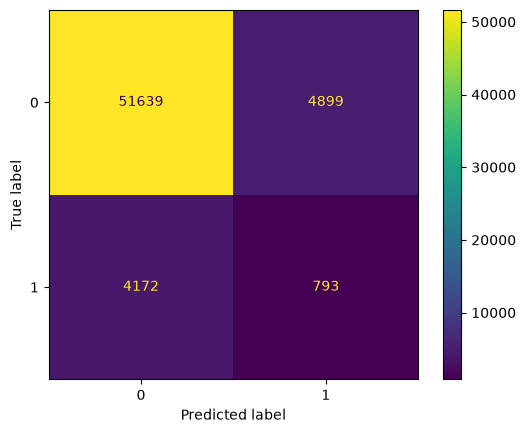

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_valid_pred = model.predict(X_valid)

cm = confusion_matrix(y_valid, y_valid_pred)

display_cm = ConfusionMatrixDisplay(confusion_matrix=cm)
display_cm.plot()

plt.show()

Аналіз помилок

In [26]:
tn, fp, fn, tp = cm.ravel()

print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

print()

print("Загальна кількість помилок:")
print(fp + fn)

True Negative: 51639
False Positive: 4899
False Negative: 4172
True Positive: 793

Загальна кількість помилок:
9071


Модель правильно класифікувала 51639 об'єктів класу 0 та 793 об'єкти класу 1. При цьому отримано 4899 False Positive та 4172 False Negative прогнозів. Значення ROC-AUC = 0.537 свідчить про низьку здатність базової моделі розрізняти класи.

Формування прогнозу для тестових даних

In [29]:
model.fit(X, y)

test_proba = model.predict_proba(test_processed)[:, 1]

print("Кількість прогнозів:")
print(len(test_proba))

Кількість прогнозів:
48744


Створення submission-файлу

In [31]:
submission = pd.DataFrame({
    "SK_ID_CURR": test_ids,
    "TARGET": test_proba
})

display(submission.head())

submission.to_csv("submission.csv", index=False)

print()
print("Файл submission.csv створено")

,SK_ID_CURR,TARGET
0,100001,0.0
1,100005,0.0
2,100013,0.0
3,100028,0.0
4,100038,0.0



Файл submission.csv створено
